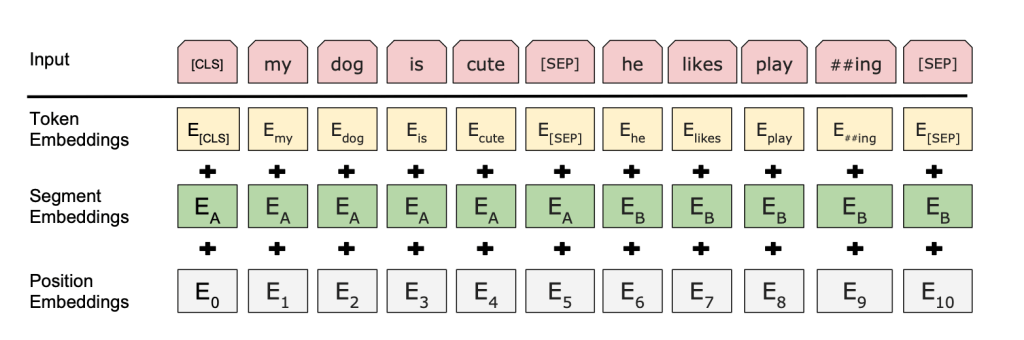

### summary
- bert input embedding：一种查表操作（lookup table）
  - 查表
    - token embeddings：30522*768
    - segment embeddings：2*768
    - position embeddings: 512*768
  - 后处理
    - layer norm
    - dropout

In [1]:
from transformers import BertTokenizer, BertModel
import torch
from torch import nn

In [2]:
model_name = "bert-base-uncased"

In [3]:
tokenizer = BertTokenizer.from_pretrained(model_name)

In [4]:
bert = BertModel.from_pretrained(model_name)

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.seq_relationship.weight', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [5]:
tokenizer

BertTokenizer(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, is_fast=False, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'})

In [6]:
test_cent = "It is a test sentence"

In [7]:
token = tokenizer(test_cent, return_tensors="pt")
token

{'input_ids': tensor([[ 101, 2009, 2003, 1037, 3231, 6251,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1]])}

In [8]:
input_ids = token.get("input_ids")
input_ids

tensor([[ 101, 2009, 2003, 1037, 3231, 6251,  102]])

In [9]:
token_type_ids = token.get("token_type_ids")

In [10]:
pos_ids = torch.arange(len(input_ids))

In [11]:
pos_ids

tensor([0])

In [12]:
tokenizer.decode([2009])

'it'

## 1. token embedding

In [13]:
token_embedding = bert.embeddings.word_embeddings(input_ids)
token_embedding.shape
token_embedding

tensor([[[ 0.0136, -0.0265, -0.0235,  ...,  0.0087,  0.0071,  0.0151],
         [-0.0449, -0.0279, -0.0088,  ...,  0.0133,  0.0185,  0.0093],
         [-0.0360, -0.0246, -0.0257,  ...,  0.0034, -0.0018,  0.0269],
         ...,
         [ 0.0237, -0.0614, -0.0296,  ..., -0.0102, -0.0072, -0.1174],
         [ 0.0321,  0.0063, -0.0064,  ..., -0.0012, -0.1081, -0.0895],
         [-0.0145, -0.0100,  0.0060,  ..., -0.0250,  0.0046, -0.0015]]],
       grad_fn=<EmbeddingBackward0>)

## 2. Segment type embedding

In [14]:
seg_embedding = bert.embeddings.token_type_embeddings(token_type_ids)
print(seg_embedding.shape)
seg_embedding

torch.Size([1, 7, 768])


tensor([[[ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086],
         [ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086],
         [ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086],
         ...,
         [ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086],
         [ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086],
         [ 0.0004,  0.0110,  0.0037,  ..., -0.0066, -0.0034, -0.0086]]],
       grad_fn=<EmbeddingBackward0>)

## 3. pos embedding

In [15]:
seg_embedding = bert.embeddings.position_embeddings(pos_ids)

In [16]:
print(seg_embedding.shape)
seg_embedding

torch.Size([1, 768])


tensor([[ 1.7505e-02, -2.5631e-02, -3.6642e-02, -2.5286e-02,  7.9709e-03,
         -2.0358e-02, -3.7631e-03, -4.6880e-03,  6.2253e-03, -3.8342e-02,
          1.3103e-02, -3.7083e-03, -2.1014e-02,  1.1626e-02, -3.9546e-02,
          1.0155e-02,  1.8081e-03, -3.9818e-03,  1.6112e-02, -1.9327e-02,
         -3.1684e-02, -2.5482e-02,  3.2621e-04,  2.0337e-02, -1.6705e-02,
         -2.1000e-02, -7.8122e-03,  1.5647e-02, -6.3413e-03,  5.5291e-03,
         -1.5590e-02,  4.1118e-03, -1.8160e-02,  2.1867e-03,  7.1782e-03,
         -1.5383e-02, -3.2506e-03,  1.5954e-02,  1.8287e-02,  3.6061e-02,
         -3.9159e-03,  4.1934e-03, -9.5806e-03, -5.0352e-03, -4.4547e-03,
          2.0729e-03, -3.2415e-01,  3.4504e-03,  4.6929e-02, -2.1057e-02,
          5.6190e-02,  2.3602e-02, -2.3394e-02,  2.1003e-01,  3.3293e-02,
         -7.0262e-03, -9.4291e-03, -3.4105e-04,  2.4235e-02, -2.2936e-02,
          1.3023e-02,  6.9495e-03, -1.2559e-01, -8.3786e-03,  6.9158e-04,
         -9.6908e-03,  1.1022e-02, -1.

## 4. Input embedding

In [17]:
input_embed =  token_embedding+seg_embedding+seg_embedding

In [18]:
input_embed.shape

torch.Size([1, 7, 768])

In [19]:
input_embed

tensor([[[ 0.0486, -0.0778, -0.0968,  ...,  0.0087,  0.0085,  0.0460],
         [-0.0099, -0.0791, -0.0821,  ...,  0.0134,  0.0199,  0.0402],
         [-0.0010, -0.0759, -0.0990,  ...,  0.0034, -0.0005,  0.0577],
         ...,
         [ 0.0587, -0.1126, -0.1029,  ..., -0.0102, -0.0059, -0.0866],
         [ 0.0671, -0.0449, -0.0797,  ..., -0.0011, -0.1067, -0.0586],
         [ 0.0205, -0.0612, -0.0673,  ..., -0.0250,  0.0060,  0.0293]]],
       grad_fn=<AddBackward0>)